[![Open In Colab](https://colab.research.google.com/assets/colab-badge.svg)](https://colab.research.google.com/github/bihjane/data-science-and-ai-k-12-teaching-tools/blob/main/intelligent-futures-free-courses/colab-notebooks/03_life_expectancy_regression_gapminder.ipynb)

# Predicting life expectancy around the world
**Level:** intermediate · **Time:** 60 minutes · **Models:** linear regression, random forest

**Question:** How well can a country's income per person predict its life expectancy? Does adding the continent help?

Data: Gapminder (142 countries, every 5 years from 1952 to 2007), built into the free `plotly` library.

Full model steps: load, explore, transform, encode, split, train, evaluate, compare, interpret, predict.

## How to use this notebook
1. Click **Open in Colab** above, or upload this file at [colab.research.google.com](https://colab.research.google.com) (File > Upload notebook).
2. Run each code cell in order with **Shift + Enter**.
3. Before running a cell, **predict** what it will show. After running it, check your prediction.
4. Try the **Your turn** tasks at the end of each step.

No installs or downloads are needed. Everything runs free in your browser.

## Step 1. Load the data

In [1]:
import pandas as pd, numpy as np, matplotlib.pyplot as plt
import plotly.express as px

gm = px.data.gapminder()
print(gm.shape)
gm.head()

(1704, 8)


,country,continent,year,lifeExp,pop,gdpPercap,iso_alpha,iso_num
0,Afghanistan,Asia,1952,28.801,8425333,779.445314,AFG,4
1,Afghanistan,Asia,1957,30.332,9240934,820.853030,AFG,4
2,Afghanistan,Asia,1962,31.997,10267083,853.100710,AFG,4
3,Afghanistan,Asia,1967,34.020,11537966,836.197138,AFG,4
4,Afghanistan,Asia,1972,36.088,13079460,739.981106,AFG,4


**Columns:** country, continent, year, lifeExp (years), pop, gdpPercap (income per person, US dollars adjusted for inflation).

## Step 2. Explore

In [2]:
latest = gm[gm.year == 2007]
fig = px.scatter(latest, x="gdpPercap", y="lifeExp", color="continent", size="pop",
                 hover_name="country", log_x=True, title="Income and life expectancy, 2007")
fig.show()

Income is on a **log scale**: each step is 10 times richer. On this scale the pattern looks close to a straight line.

## Step 3. Prepare the features
- Take the log of income so a straight line fits.
- Turn the continent (a category) into 0/1 columns (**one-hot encoding**).

In [3]:
data = gm.copy()
data["log_gdp"] = np.log10(data.gdpPercap)
X = pd.get_dummies(data[["log_gdp", "year", "continent"]], columns=["continent"], drop_first=True)
y = data["lifeExp"]
X.head()

,log_gdp,year,continent_Americas,continent_Asia,continent_Europe,continent_Oceania
0,2.891786,1952,False,True,False,False
1,2.914265,1957,False,True,False,False
2,2.931000,1962,False,True,False,False
3,2.922309,1967,False,True,False,False
4,2.869221,1972,False,True,False,False


## Step 4. Split into training and test sets
We hide 20% of countries completely, so the test is fair.

In [4]:
from sklearn.model_selection import GroupShuffleSplit

split = GroupShuffleSplit(test_size=0.2, random_state=42)
train_idx, test_idx = next(split.split(X, y, groups=data.country))
X_train, X_test = X.iloc[train_idx], X.iloc[test_idx]
y_train, y_test = y.iloc[train_idx], y.iloc[test_idx]
print("train rows:", len(X_train), " test rows:", len(X_test))
print("test countries include:", sorted(data.country.iloc[test_idx].unique())[:8])

train rows: 1356  test rows: 348
test countries include: ['Argentina', 'Belgium', 'Bolivia', 'Bosnia and Herzegovina', 'Cambodia', 'Cameroon', 'Comoros', 'Congo, Dem. Rep.']


## Step 5. Train three models

In [5]:
from sklearn.linear_model import LinearRegression
from sklearn.ensemble import RandomForestRegressor
from sklearn.metrics import mean_absolute_error

models = {
    "Income only (linear)": (LinearRegression(), ["log_gdp"]),
    "All features (linear)": (LinearRegression(), list(X.columns)),
    "All features (random forest)": (RandomForestRegressor(n_estimators=300, random_state=42), list(X.columns)),
}
baseline = mean_absolute_error(y_test, [y_train.mean()] * len(y_test))
print(f"Baseline (always guess the average): {baseline:.1f} years off")
for name, (m, cols) in models.items():
    m.fit(X_train[cols], y_train)
    err = mean_absolute_error(y_test, m.predict(X_test[cols]))
    print(f"{name:32s} {err:.1f} years off on average")

Baseline (always guess the average): 11.7 years off
Income only (linear)             6.1 years off on average
All features (linear)            5.1 years off on average


All features (random forest)     5.0 years off on average


## Step 6. Interpret the linear model

In [6]:
lin = models["All features (linear)"][0]
pd.Series(lin.coef_, index=X.columns).round(2)

log_gdp               11.28
year                   0.24
continent_Americas     9.16
continent_Asia         7.20
continent_Europe      13.04
continent_Oceania     13.13
dtype: float64

- **log_gdp:** life expectancy gained for each 10-times increase in income, other things equal.
- **year:** years of life expectancy gained per calendar year.
- **continent_...:** difference from Africa (the baseline group).

Correlation is not cause: income, health care, education and clean water all move together.

## Step 7. Check the errors

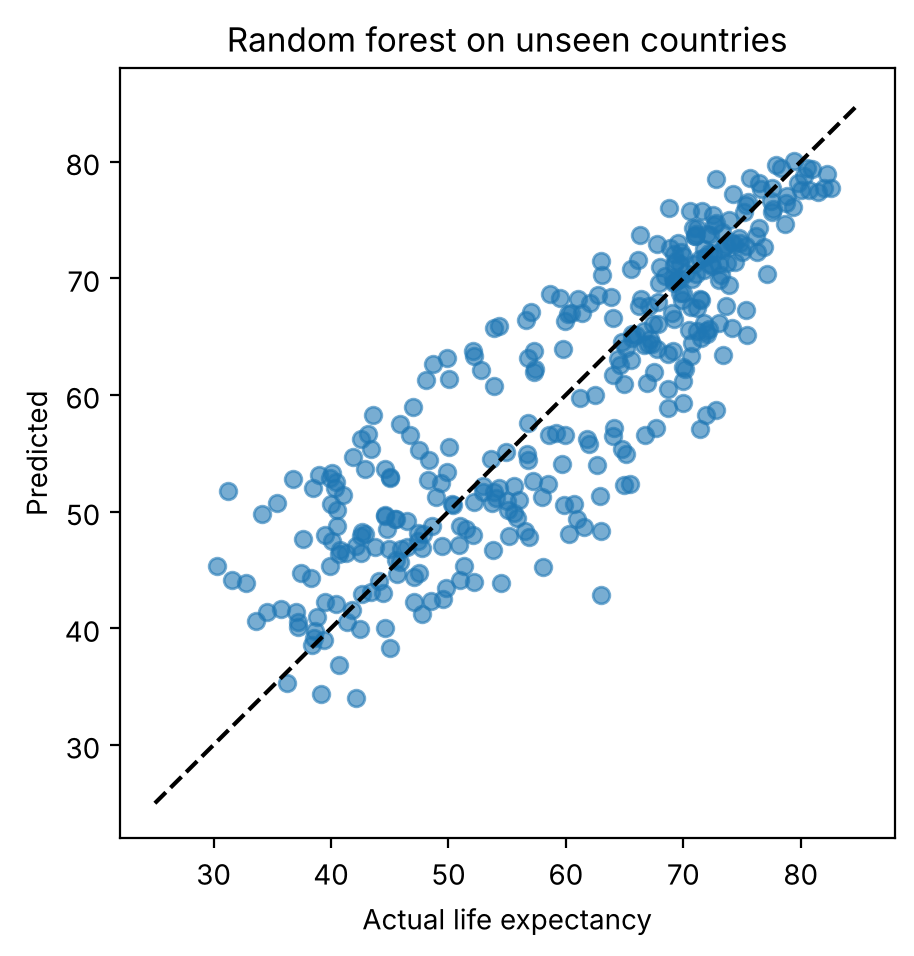

,country,year,lifeExp,pred
221,Cambodia,1977,31.220,51.736262
322,Comoros,2002,62.974,42.832800
1349,Sierra Leone,1977,36.788,52.795223
1347,Sierra Leone,1967,34.113,49.795237
1348,Sierra Leone,1972,35.400,50.704420


In [7]:
rf = models["All features (random forest)"][0]
pred = rf.predict(X_test)
plt.figure(figsize=(5,5))
plt.scatter(y_test, pred, alpha=0.6)
plt.plot([25, 85], [25, 85], "k--")
plt.xlabel("Actual life expectancy"); plt.ylabel("Predicted"); plt.title("Random forest on unseen countries")
plt.show()

worst = data.iloc[test_idx].assign(pred=pred, err=(pred - y_test).abs()).sort_values("err", ascending=False)
worst[["country", "year", "lifeExp", "pred"]].head(5)

**Your turn:** Look at the largest errors. What events in those countries and years might the model not know about?

## Step 8. Use the model

In [8]:
new = pd.DataFrame({"log_gdp": [np.log10(2000), np.log10(20000)], "year": [2007, 2007]})
for c in [col for col in X.columns if col.startswith("continent_")]:
    new[c] = 0
new["continent_Asia"] = 1     # two hypothetical Asian countries
print(new[X.columns])
print("Predicted life expectancy:", rf.predict(new[X.columns]).round(1))

   log_gdp  year  continent_Americas  continent_Asia  continent_Europe  \
0  3.30103  2007                   0               1                 0   
1  4.30103  2007                   0               1                 0   

   continent_Oceania  
0                  0  
1                  0  


Predicted life expectancy: [62.7 77.3]


## Your turn: extensions
1. Predict life expectancy for your own country's income and continent.
2. Add population (`log10(pop)`) as a feature. Does the error drop?
3. Write a short **model card**: purpose, data, error, limits and who could be harmed by misuse.

---
*Intelligent Futures · Dr. Bih Janet Shufor · Free for classroom use with attribution.*